In [1]:
# CELL 1: IMPORT LIBRARIES

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# CELL 2: LOAD THE 20 NEWSGROUPS DATASET

print("Downloading and loading the dataset...")

news_data = fetch_20newsgroups(
    subset="all",
    remove=("headers", "footers", "quotes")
)

df = pd.DataFrame({
    "text": news_data.data,
    "category": [
        news_data.target_names[label]
        for label in news_data.target
    ]
})

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumns:", df.columns.tolist())
print("Number of documents:", len(df))
print("Number of categories:", df["category"].nunique())

Dataset loaded successfully!
Dataset shape: (18846, 2)


,text,category
0,\n\nI am sure some bashers of Pens fans are pr...,rec.sport.hockey
1,My brother is in the market for a high-perform...,comp.sys.ibm.pc.hardware
2,\n\n\n\n\tFinally you said what you dream abou...,talk.politics.mideast
3,\nThink!\n\nIt's the SCSI card doing the DMA t...,comp.sys.ibm.pc.hardware
4,1) I have an old Jasmine drive which I cann...,comp.sys.mac.hardware



Columns: ['text', 'category']
Number of documents: 18846
Number of categories: 20


In [3]:
# CELL 3: DATASET INSPECTION

print("Dataset information:")
print(df.info())

print("\nFirst three documents:")
display(df.head(3))

print("\nCategory names:")
print(sorted(df["category"].unique()))

print("\nMissing values:")
print(df.isnull().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18846 entries, 0 to 18845
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      18846 non-null  object
 1   category  18846 non-null  object
dtypes: object(2)
memory usage: 294.6+ KB
None

First three documents:


,text,category
0,\n\nI am sure some bashers of Pens fans are pr...,rec.sport.hockey
1,My brother is in the market for a high-perform...,comp.sys.ibm.pc.hardware
2,\n\n\n\n\tFinally you said what you dream abou...,talk.politics.mideast



Category names:
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Missing values:
text        0
category    0
dtype: int64


In [4]:
# CELL 4: DATA CLEANING

df = df.dropna(subset=["text", "category"]).copy()

df["text"] = df["text"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip()

df = df[
    (df["text"] != "") &
    (df["category"] != "")
]

df = df.drop_duplicates(
    subset=["text"]
).reset_index(drop=True)

print("Documents after cleaning:", len(df))

print("\nClass labels:")
print(sorted(df["category"].unique()))

print("\nNumber of categories:", df["category"].nunique())

Documents after cleaning: 18262

Class labels:
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Number of categories: 20


,Documents,Percentage
category,,
alt.atheism,779,4.27
comp.graphics,951,5.21
comp.os.ms-windows.misc,943,5.16
comp.sys.ibm.pc.hardware,960,5.26
comp.sys.mac.hardware,927,5.08
comp.windows.x,963,5.27
misc.forsale,943,5.16
rec.autos,936,5.13
rec.motorcycles,967,5.30


Largest class: 975
Smallest class: 605
Largest-to-smallest class ratio: 1.61


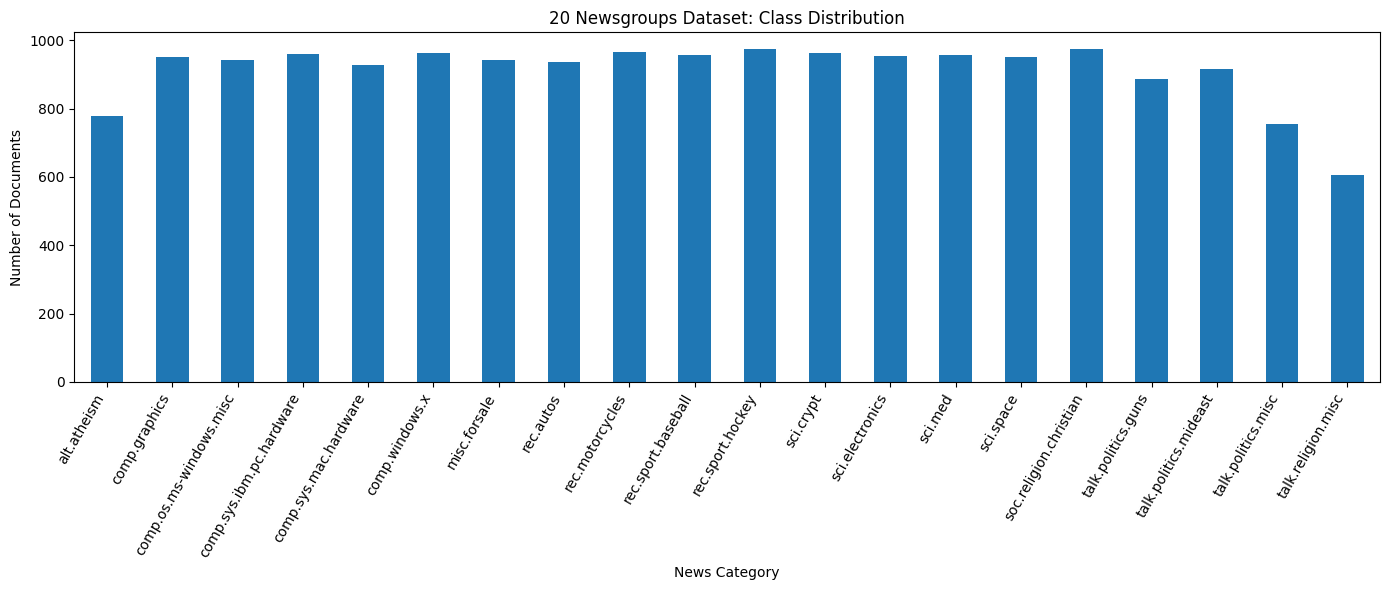

In [5]:
# CELL 5: CLASS DISTRIBUTION

class_counts = df["category"].value_counts().sort_index()

distribution = pd.DataFrame({
    "Documents": class_counts,
    "Percentage": (
        class_counts / len(df) * 100
    ).round(2)
})

display(distribution)

print("Largest class:", class_counts.max())
print("Smallest class:", class_counts.min())

print(
    "Largest-to-smallest class ratio:",
    round(class_counts.max() / class_counts.min(), 2)
)

plt.figure(figsize=(14, 6))

class_counts.plot(kind="bar")

plt.title("20 Newsgroups Dataset: Class Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Documents")
plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()

In [6]:
# CELL 6: TRAIN-TEST SPLIT

X = df["text"]
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training documents:", len(X_train))
print("Testing documents:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training documents: 14609
Testing documents: 3653

Training class distribution:
category
alt.atheism                 623
comp.graphics               761
comp.os.ms-windows.misc     754
comp.sys.ibm.pc.hardware    768
comp.sys.mac.hardware       742
comp.windows.x              770
misc.forsale                754
rec.autos                   749
rec.motorcycles             773
rec.sport.baseball          766
rec.sport.hockey            780
sci.crypt                   769
sci.electronics             762
sci.med                     765
sci.space                   762
soc.religion.christian      780
talk.politics.guns          709
talk.politics.mideast       733
talk.politics.misc          605
talk.religion.misc          484
Name: count, dtype: int64

Testing class distribution:
category
alt.atheism                 156
comp.graphics               190
comp.os.ms-windows.misc     189
comp.sys.ibm.pc.hardware    192
comp.sys.mac.hardware       185
comp.windows.x              193
misc.forsale   

In [7]:
# CELL 8: DEFINE CLASSIFICATION MODELS

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=300
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=0.1
    )
}

print("Four classification models defined successfully!")

for name in models:
    print("-", name)

Four classification models defined successfully!
- Decision Tree
- KNN
- SVM
- Naive Bayes


In [10]:
# CELL 9: TRAIN AND EVALUATE ALL MODELS

# Initialize and fit TF-IDF Vectorizer
print("Vectorizing text data using TF-IDF...")
vectorizer = TfidfVectorizer(max_features=50000, stop_words="english")
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("Text vectorization complete!")

results = []
predictions = {}

training_times = {}
testing_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Measure training time
    start = time.perf_counter()

    model.fit(X_train_tfidf, y_train)

    training_times[name] = time.perf_counter() - start

    # Measure prediction time
    start = time.perf_counter()

    y_pred = model.predict(X_test_tfidf)

    testing_times[name] = time.perf_counter() - start

    predictions[name] = y_pred

    # Calculate evaluation metrics
    results.append({
        "Model": name,

        "Accuracy": accuracy_score(y_test, y_pred),

        "Precision (weighted)": precision_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),

        "Recall (weighted)": recall_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1-score (weighted)": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1-score (macro)": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "Training time (s)": training_times[name],

        "Testing time (s)": testing_times[name]
    })

    print(f"{name} completed.")

results_df = pd.DataFrame(results)

print("\nAll four models trained and evaluated!")

display(results_df.round(4))

Vectorizing text data using TF-IDF...
Text vectorization complete!

Training Decision Tree...
Decision Tree completed.

Training KNN...
KNN completed.

Training SVM...
SVM completed.

Training Naive Bayes...
Naive Bayes completed.

All four models trained and evaluated!


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),F1-score (macro),Training time (s),Testing time (s)
0,Decision Tree,0.4812,0.5279,0.4812,0.4949,0.4858,26.4963,0.0057
1,KNN,0.6866,0.6995,0.6866,0.6884,0.6821,0.0277,2.4150
2,SVM,0.7758,0.7752,0.7758,0.7748,0.7671,1.4923,0.0063
3,Naive Bayes,0.7878,0.7969,0.7878,0.7840,0.7752,0.0818,0.0086


In [11]:
# CELL 10: MODEL RANKING

comparison = results_df.sort_values(
    by="F1-score (weighted)",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL RANKING")

display(comparison.round(4))

best_model_name = comparison.loc[0, "Model"]

print("\nBest model by weighted F1:", best_model_name)

print(
    "Weighted F1-score:",
    round(comparison.loc[0, "F1-score (weighted)"], 4)
)

print(
    "Accuracy:",
    round(comparison.loc[0, "Accuracy"], 4)
)

FINAL MODEL RANKING


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),F1-score (macro),Training time (s),Testing time (s)
0,Naive Bayes,0.7878,0.7969,0.7878,0.7840,0.7752,0.0818,0.0086
1,SVM,0.7758,0.7752,0.7758,0.7748,0.7671,1.4923,0.0063
2,KNN,0.6866,0.6995,0.6866,0.6884,0.6821,0.0277,2.4150
3,Decision Tree,0.4812,0.5279,0.4812,0.4949,0.4858,26.4963,0.0057



Best model by weighted F1: Naive Bayes
Weighted F1-score: 0.784
Accuracy: 0.7878


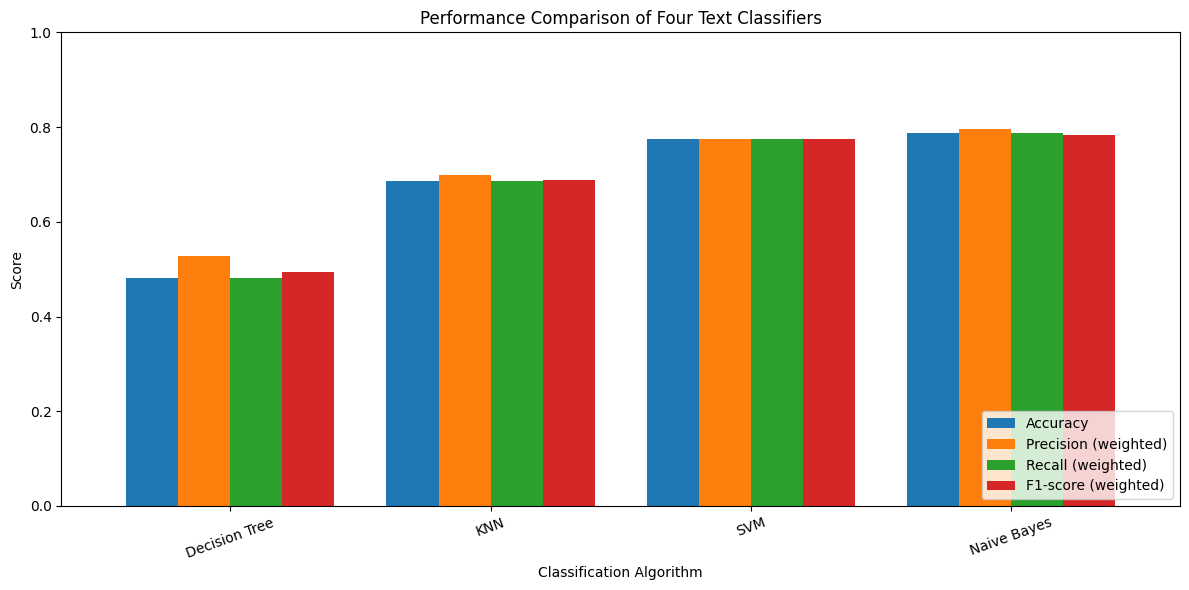

In [12]:
# CELL 11: PERFORMANCE COMPARISON GRAPH

metric_cols = [
    "Accuracy",
    "Precision (weighted)",
    "Recall (weighted)",
    "F1-score (weighted)"
]

plot_df = results_df.set_index("Model")[metric_cols]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Performance Comparison of Four Text Classifiers")
ax.set_xlabel("Classification Algorithm")
ax.set_ylabel("Score")

ax.legend(loc="lower right")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

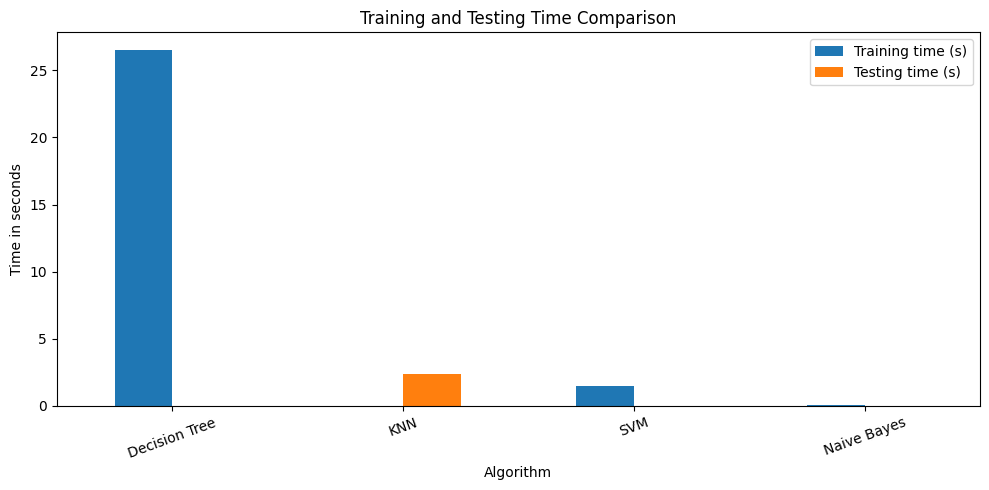

In [13]:
# CELL 12: EXECUTION TIME COMPARISON

time_df = results_df.set_index("Model")[
    ["Training time (s)", "Testing time (s)"]
]

time_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Training and Testing Time Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Time in seconds")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

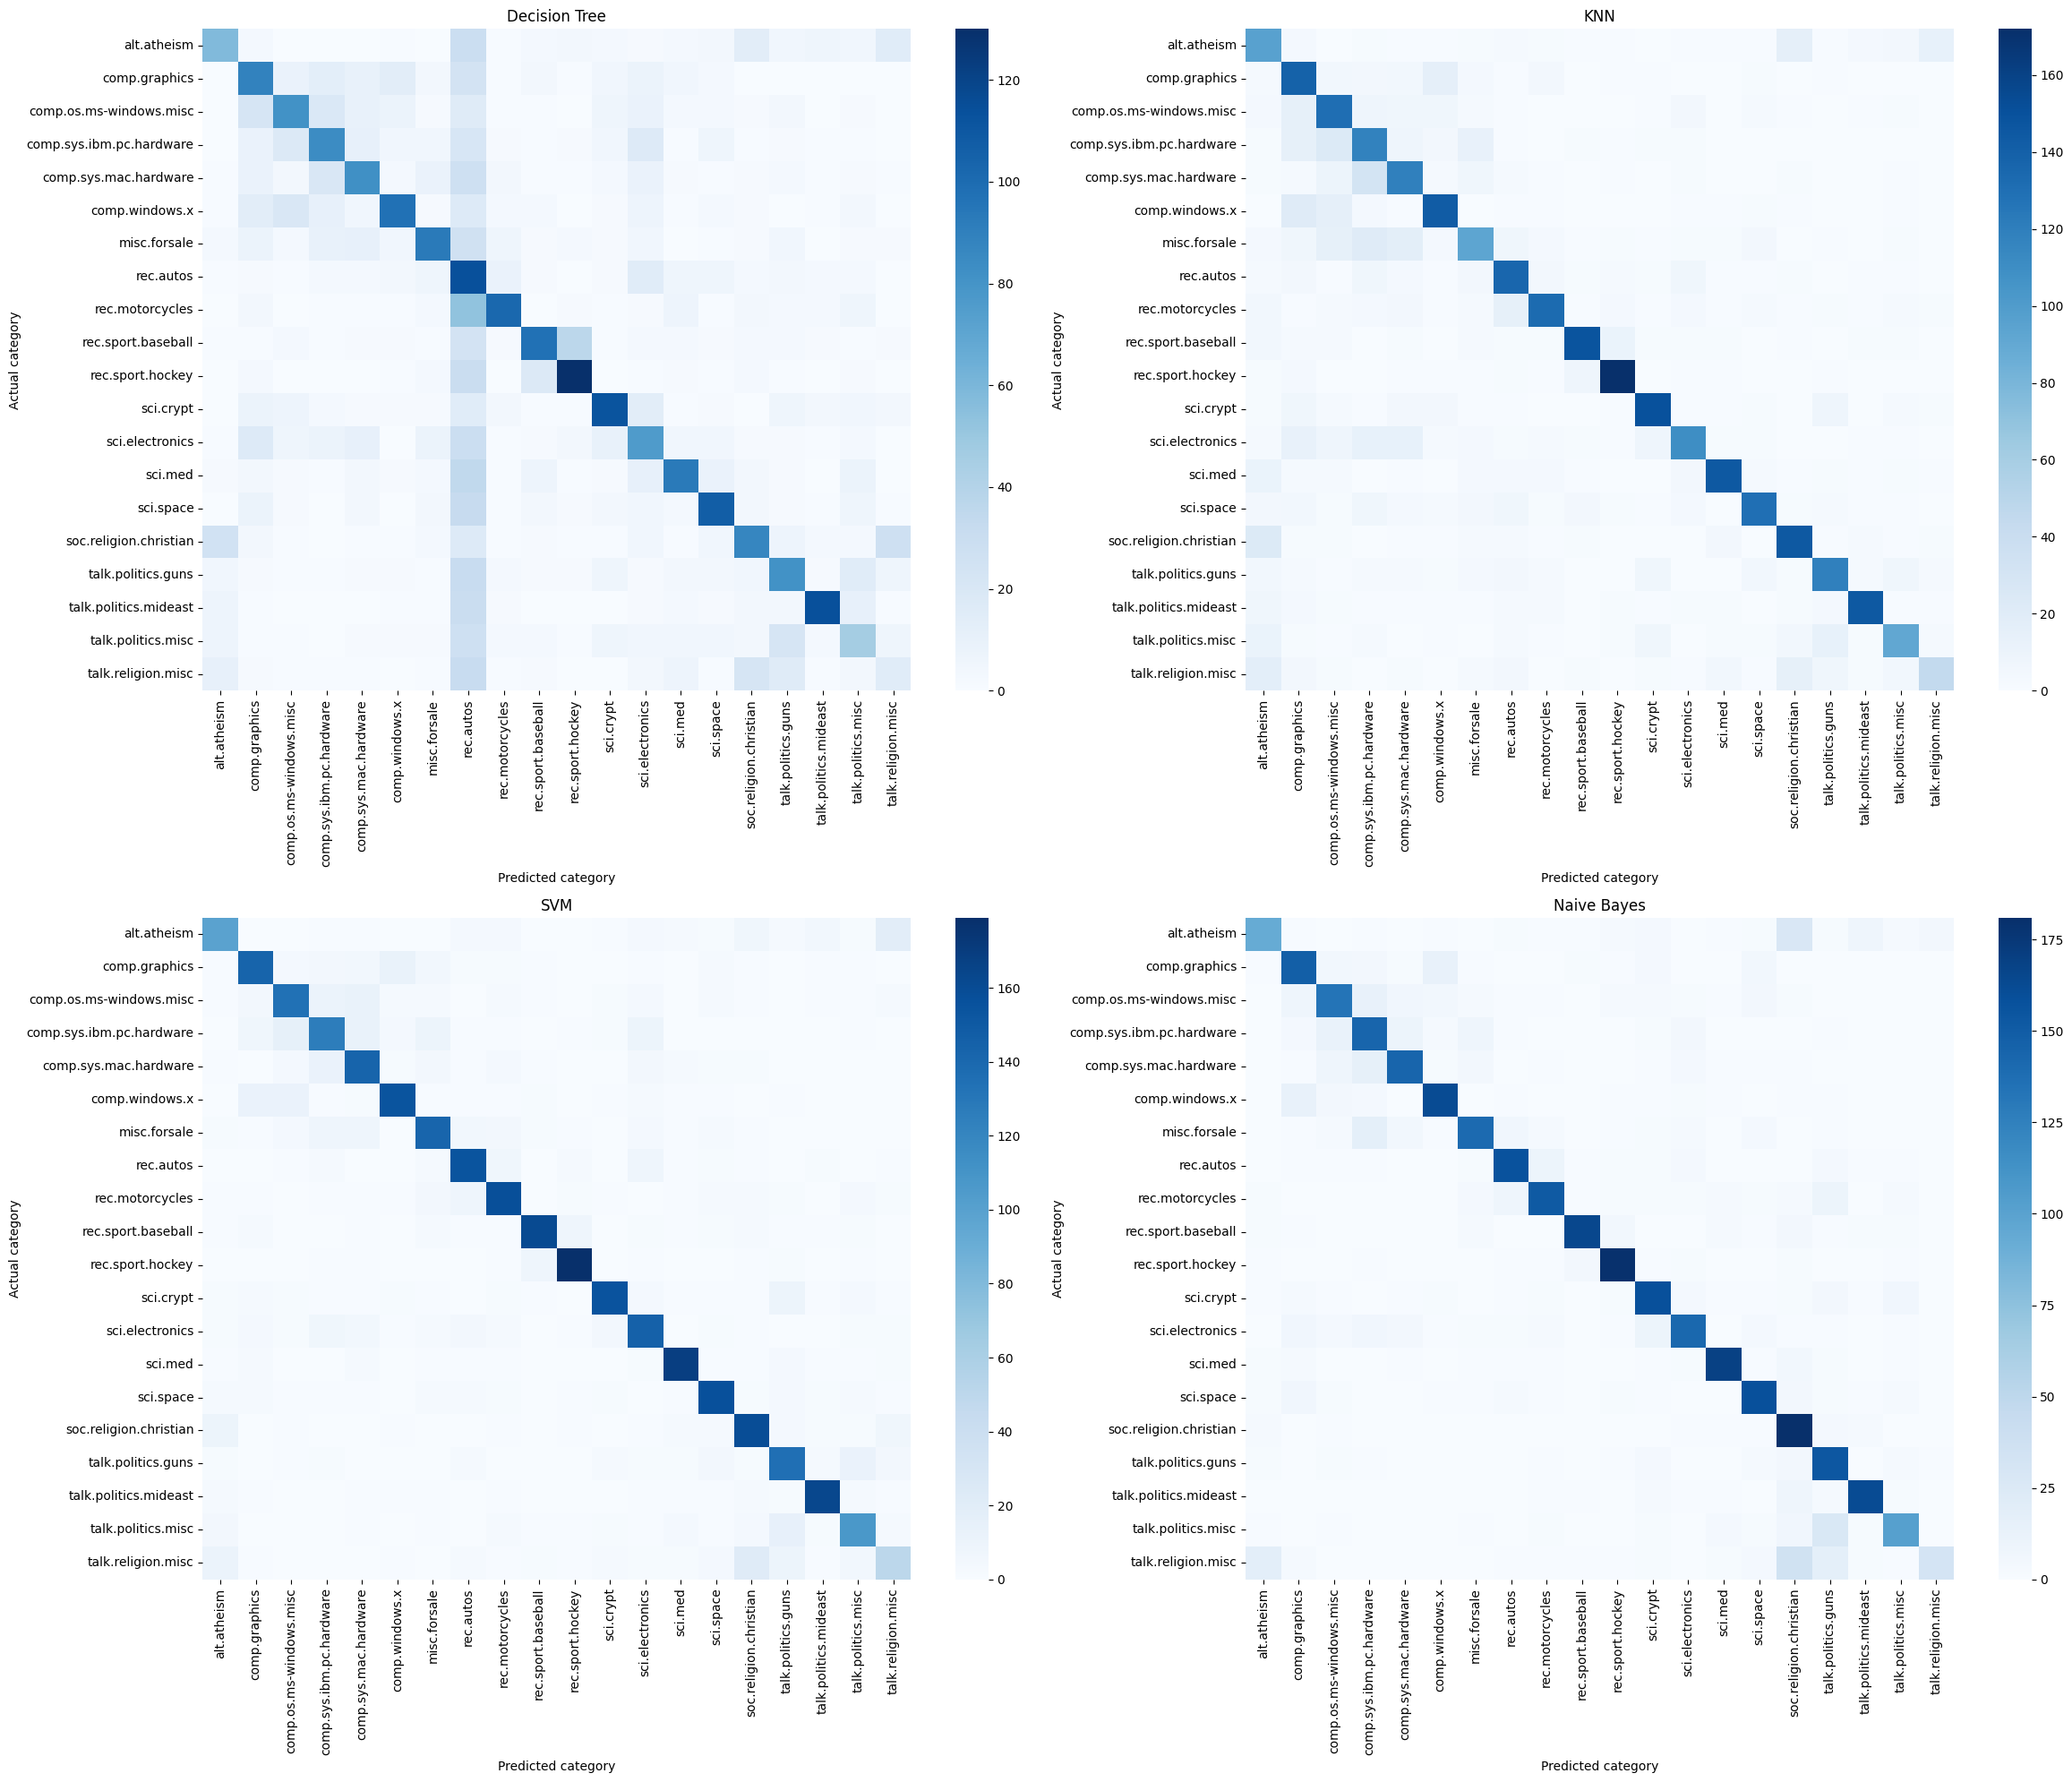

In [15]:
# CELL 13: CONFUSION MATRICES FOR ALL FOUR MODELS

class_names = sorted(y.unique())

fig, axes = plt.subplots(
    2, 2,
    figsize=(24, 20)
)

for ax, (name, y_pred) in zip(
    axes.flatten(),
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_names
    )

    sns.heatmap(
        cm,
        annot=False,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted category")
    ax.set_ylabel("Actual category")

    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [16]:
# CELL 14: BEST MODEL CLASSIFICATION REPORT

best_model_name = comparison.loc[0, "Model"]

best_predictions = predictions[best_model_name]

print("Selected model:", best_model_name)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        best_predictions,
        labels=class_names,
        zero_division=0
    )
)

best_cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_names
)

print("\nConfusion Matrix:")
print(best_cm)

Selected model: Naive Bayes

Classification Report:

                          precision    recall  f1-score   support

             alt.atheism       0.73      0.60      0.65       156
           comp.graphics       0.73      0.78      0.76       190
 comp.os.ms-windows.misc       0.74      0.70      0.72       189
comp.sys.ibm.pc.hardware       0.68      0.75      0.71       192
   comp.sys.mac.hardware       0.82      0.78      0.80       185
          comp.windows.x       0.84      0.84      0.84       193
            misc.forsale       0.81      0.74      0.78       189
               rec.autos       0.84      0.84      0.84       187
         rec.motorcycles       0.84      0.78      0.81       194
      rec.sport.baseball       0.93      0.86      0.90       191
        rec.sport.hockey       0.87      0.92      0.90       195
               sci.crypt       0.78      0.82      0.80       193
         sci.electronics       0.82      0.74      0.78       191
                 sci.m

In [17]:
# CELL 15: KNN WHAT-IF EXPERIMENT

knn_results = []

for k in [3, 5, 7]:

    print(f"\nTesting KNN with K = {k}")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    # Training time
    start = time.perf_counter()

    knn.fit(X_train_tfidf, y_train)

    train_time = time.perf_counter() - start

    # Testing time
    start = time.perf_counter()

    pred = knn.predict(X_test_tfidf)

    test_time = time.perf_counter() - start

    knn_results.append({
        "K": k,

        "Accuracy": accuracy_score(y_test, pred),

        "Precision": precision_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),

        "Training time (s)": train_time,

        "Testing time (s)": test_time
    })

knn_df = pd.DataFrame(knn_results)

print("\nKNN Experiment Results:")

display(knn_df.round(4))


Testing KNN with K = 3

Testing KNN with K = 5

Testing KNN with K = 7

KNN Experiment Results:


,K,Accuracy,Precision,Recall,Weighted F1,Training time (s),Testing time (s)
0,3,0.6480,0.6740,0.6480,0.6525,0.0314,4.3090
1,5,0.6866,0.6995,0.6866,0.6884,0.0621,3.3072
2,7,0.7008,0.7058,0.7008,0.7005,0.0280,3.5555


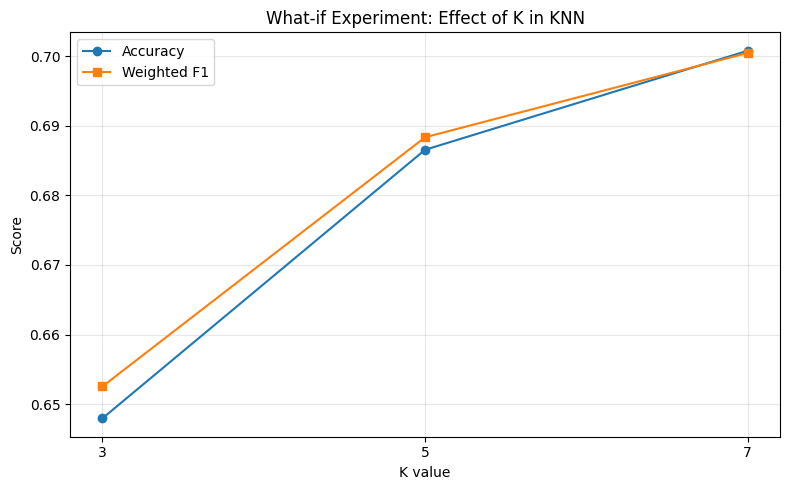

Best K by weighted F1: 7


In [18]:
# CELL 16: EFFECT OF K ON KNN PERFORMANCE

plt.figure(figsize=(8, 5))

plt.plot(
    knn_df["K"],
    knn_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_df["K"],
    knn_df["Weighted F1"],
    marker="s",
    label="Weighted F1"
)

plt.xticks([3, 5, 7])

plt.xlabel("K value")
plt.ylabel("Score")

plt.title("What-if Experiment: Effect of K in KNN")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_knn_row = knn_df.loc[
    knn_df["Weighted F1"].idxmax()
]

print(
    "Best K by weighted F1:",
    int(best_knn_row["K"])
)

In [19]:
# CELL 17: FINAL MODEL RANKING

comparison = results_df.sort_values(
    by="F1-score (weighted)",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL RANKING")

display(comparison.round(4))

best_model_name = comparison.loc[0, "Model"]

print("\nBest model:", best_model_name)

print(
    "Weighted F1-score:",
    round(
        comparison.loc[0, "F1-score (weighted)"],
        4
    )
)

print(
    "Accuracy:",
    round(
        comparison.loc[0, "Accuracy"],
        4
    )
)

for name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=class_names,
            zero_division=0
        )
    )

FINAL MODEL RANKING


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),F1-score (macro),Training time (s),Testing time (s)
0,Naive Bayes,0.7878,0.7969,0.7878,0.7840,0.7752,0.0818,0.0086
1,SVM,0.7758,0.7752,0.7758,0.7748,0.7671,1.4923,0.0063
2,KNN,0.6866,0.6995,0.6866,0.6884,0.6821,0.0277,2.4150
3,Decision Tree,0.4812,0.5279,0.4812,0.4949,0.4858,26.4963,0.0057



Best model: Naive Bayes
Weighted F1-score: 0.784
Accuracy: 0.7878

Decision Tree
                          precision    recall  f1-score   support

             alt.atheism       0.47      0.37      0.42       156
           comp.graphics       0.42      0.47      0.44       190
 comp.os.ms-windows.misc       0.51      0.43      0.46       189
comp.sys.ibm.pc.hardware       0.48      0.44      0.46       192
   comp.sys.mac.hardware       0.51      0.44      0.47       185
          comp.windows.x       0.64      0.50      0.56       193
            misc.forsale       0.61      0.49      0.54       189
               rec.autos       0.18      0.61      0.28       187
         rec.motorcycles       0.69      0.53      0.60       194
      rec.sport.baseball       0.63      0.51      0.56       191
        rec.sport.hockey       0.68      0.67      0.67       195
               sci.crypt       0.65      0.58      0.62       193
         sci.electronics       0.38      0.40      0.39    

In [20]:
# CELL 18: EXPORT RESULTS TO CSV

results_df.to_csv(
    "classifier_comparison.csv",
    index=False
)

knn_df.to_csv(
    "knn_what_if_results.csv",
    index=False
)

print("Results files created successfully!")

Results files created successfully!


In [21]:
# CELL 19: DOWNLOAD RESULT FILES

from google.colab import files

files.download("classifier_comparison.csv")

files.download("knn_what_if_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>